# 03 — ML Prototype Deep Dive: Urban Heat Pattern Explorer

This notebook walks step by step through our **2,507-tile, 36-neighborhood** machine learning pipeline (**0 API credits**).

### What You Will Learn Here
1. **Anti-Leakage Feature Design** — Why we test *Urban Form Only* vs. *Urban Form + Macro-Geography* and exclude raw coordinates / `min_temperature` / `max_temperature`.
2. **Spatial Leakage Proof (`KFold` vs `GroupKFold`)** — A live side-by-side demonstration showing how standard random splits "cheat" on spatial data and why holding out entire neighborhoods is mandatory.
3. **How Each of Our 5 Models Works** — Intuition for `DummyRegressor`, `Ridge`, `RandomForest`, `ExtraTrees`, and `HistGradientBoosting`.
4. **Spatial-CV Evaluation (`MAE`, `RMSE`, `R²`)** — Full comparison across both feature sets.
5. **Interpretability (`Ridge` Coefficients & Permutation Importance)** — What physical drivers the models actually rely on.
6. **Error / Residual Analysis** — Which specific LA neighborhoods are hardest to predict and why.
7. **Within-Neighborhood Micro-Heat Experiment** — Stripping out the 15 °C coastal gradient to test whether local buildings, roads, and parks explain block-to-block heat *inside* a single neighborhood.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE = Path("..") if Path("../data/processed/urban_heat_tiles.csv").exists() else Path(".")
df = pd.read_csv(BASE / "data/processed/urban_heat_tiles.csv")
print(f"Dataset: {df.shape[0]} tiles across {df['neighborhood'].nunique()} LA neighborhoods")

Dataset: 2507 tiles across 36 LA neighborhoods


## 1. Feature Sets & Leakage Guardrails
We define two feature sets to answer two distinct questions:
* **Feature Set A (`urban_form_only`, 9 OSM features):** *Can local land cover alone (buildings, roads, parks, water, zoning) predict temperature across LA?*
* **Feature Set B (`urban_form_plus_geo`, 12 features):** *What happens when we also add physical macro-geography (`dist_to_coast_km`, `dist_to_dtla_km`, `elevation_m`)?*

> **Why exclude `centroid_lat` and `centroid_lon`?** Raw coordinates let tree models memorize specific map boxes rather than learning physical drivers like ocean cooling or elevation.

In [2]:
URBAN_FORM_FEATURES = [
    "osm_building_pct", "osm_building_count", "osm_road_length_m", "osm_major_road_m",
    "osm_green_pct", "osm_water_pct", "osm_industrial_comm_pct",
    "osm_residential_pct", "osm_parking_pct",
]
MACRO_GEO_FEATURES = ["dist_to_coast_km", "dist_to_dtla_km", "elevation_m"]
FEATURE_SETS = {
    "urban_form_only": URBAN_FORM_FEATURES,
    "urban_form_plus_geo": URBAN_FORM_FEATURES + MACRO_GEO_FEATURES,
}

y = df["average_temperature"].to_numpy()
groups = df["neighborhood"].to_numpy()
print("Set A features:", len(URBAN_FORM_FEATURES), "| Set B features:", len(FEATURE_SETS["urban_form_plus_geo"]))

Set A features: 9 | Set B features: 12


## 2. Why Spatial `GroupKFold` Matters (Random Split Leakage Demo)
If you use a standard random `KFold(shuffle=True)`, 80% of the tiles in **every** neighborhood sit in the training set. Because a 100m tile has almost the exact same temperature as the tile 100m next to it, the model effectively looks up its neighbor's answer!

Below, we run the exact same `ExtraTreesRegressor` under **Random 5-Fold KFold** vs. **Spatial 5-Fold GroupKFold** (which holds out entire neighborhoods at a time) so you can see the difference directly.

In [3]:
X_geo = df[FEATURE_SETS["urban_form_plus_geo"]]
et = ExtraTreesRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)

preds_random = cross_val_predict(et, X_geo, y, cv=KFold(n_splits=5, shuffle=True, random_state=42))
preds_spatial = cross_val_predict(et, X_geo, y, groups=groups, cv=GroupKFold(n_splits=5))

leakage_df = pd.DataFrame([
    {
        "validation_method": "Random 5-Fold KFold (LEAKY)",
        "mae_c": round(mean_absolute_error(y, preds_random), 4),
        "rmse_c": round(root_mean_squared_error(y, preds_random), 4),
        "r2": round(r2_score(y, preds_random), 4),
    },
    {
        "validation_method": "Spatial 5-Fold GroupKFold (HONEST)",
        "mae_c": round(mean_absolute_error(y, preds_spatial), 4),
        "rmse_c": round(root_mean_squared_error(y, preds_spatial), 4),
        "r2": round(r2_score(y, preds_spatial), 4),
    },
])
leakage_df

,validation_method,mae_c,rmse_c,r2
0,Random 5-Fold KFold (LEAKY),0.0952,0.1572,0.9986
1,Spatial 5-Fold GroupKFold (HONEST),0.9900,1.4114,0.8858


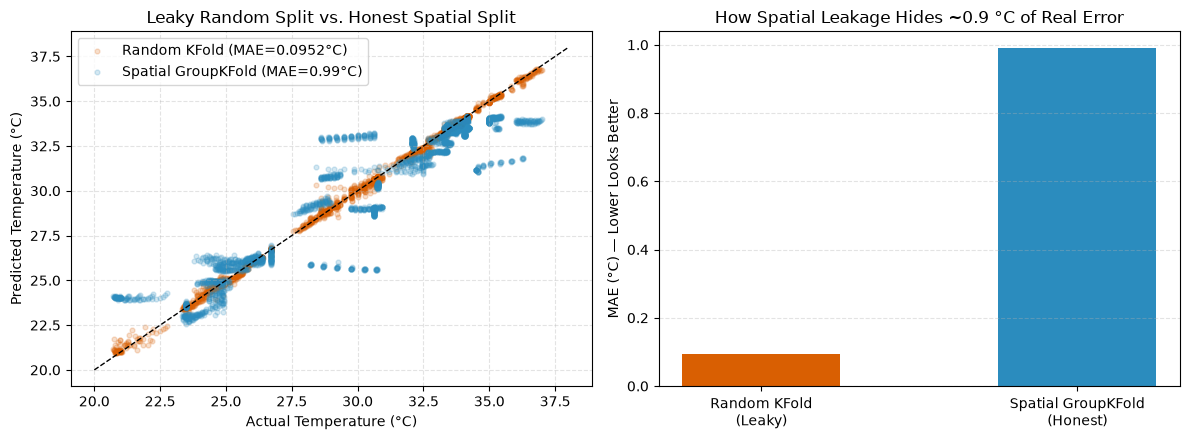

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y, preds_random, alpha=0.2, s=12, color="#d95f02", label=f"Random KFold (MAE={leakage_df.loc[0, 'mae_c']}°C)")
axes[0].scatter(y, preds_spatial, alpha=0.2, s=12, color="#2b8cbe", label=f"Spatial GroupKFold (MAE={leakage_df.loc[1, 'mae_c']}°C)")
axes[0].plot([20, 38], [20, 38], "k--", linewidth=1.0)
axes[0].set_xlabel("Actual Temperature (°C)")
axes[0].set_ylabel("Predicted Temperature (°C)")
axes[0].set_title("Leaky Random Split vs. Honest Spatial Split")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.35)

axes[1].bar(["Random KFold\n(Leaky)", "Spatial GroupKFold\n(Honest)"], leakage_df["mae_c"], color=["#d95f02", "#2b8cbe"], width=0.5)
axes[1].set_ylabel("MAE (°C) — Lower Looks Better")
axes[1].set_title("How Spatial Leakage Hides ~0.9 °C of Real Error")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## 3. Model Ladder (From Simple Baseline to Gradient Boosting)
1. **Mean Baseline (`DummyRegressor`):** Always predicts the training set mean (~30 °C). This is our sanity floor.
2. **Ridge Regression (`StandardScaler + Ridge(alpha=10)`):** Standardizes all features to mean=0, std=1 (so `elevation_m` and `osm_water_pct` are on comparable scales) and fits a regularized linear equation.
3. **Random Forest (`300` trees, `max_depth=12`, `min_samples_leaf=5`):** Averages 300 independent trees on bootstrap samples to capture non-linear thresholds without overfitting single tiles.
4. **Extra Trees (`300` trees, `max_depth=12`, `min_samples_leaf=5`):** Like Random Forest, but selects split cutoffs randomly at each node—often smoothing out noisy spatial boundaries better than greedy splits.
5. **HistGradientBoosting (`max_iter=300`, `lr=0.05`):** LightGBM-style boosting that builds trees sequentially, each correcting the residual errors of the previous ensemble.

In [5]:
def build_models():
    return {
        "Mean Baseline": DummyRegressor(strategy="mean"),
        "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0, random_state=42
        ),
    }

cv = GroupKFold(n_splits=5)
all_rows = []
oof_store = {}

for fs_name, cols in FEATURE_SETS.items():
    X = df[cols]
    oof_store[fs_name] = {}
    for m_name, model in build_models().items():
        preds = cross_val_predict(model, X, y, groups=groups, cv=cv)
        oof_store[fs_name][m_name] = preds
        all_rows.append({
            "feature_set": fs_name,
            "model": m_name,
            "mae_c": round(mean_absolute_error(y, preds), 4),
            "rmse_c": round(root_mean_squared_error(y, preds), 4),
            "r2": round(r2_score(y, preds), 4),
        })

results_df = pd.DataFrame(all_rows)
results_df

,feature_set,model,mae_c,rmse_c,r2
0,urban_form_only,Mean Baseline,3.7219,4.2184,-0.0203
1,urban_form_only,Ridge Regression,3.7327,4.2593,-0.0402
2,urban_form_only,Random Forest,3.9680,4.6824,-0.2572
3,urban_form_only,Extra Trees,3.9085,4.5342,-0.1788
4,urban_form_only,HistGradientBoosting,4.0657,4.8498,-0.3487
5,urban_form_plus_geo,Mean Baseline,3.7219,4.2184,-0.0203
6,urban_form_plus_geo,Ridge Regression,2.1889,2.7639,0.5620
7,urban_form_plus_geo,Random Forest,1.3055,2.0039,0.7697
8,urban_form_plus_geo,Extra Trees,0.9900,1.4114,0.8858
9,urban_form_plus_geo,HistGradientBoosting,1.3390,2.0437,0.7605


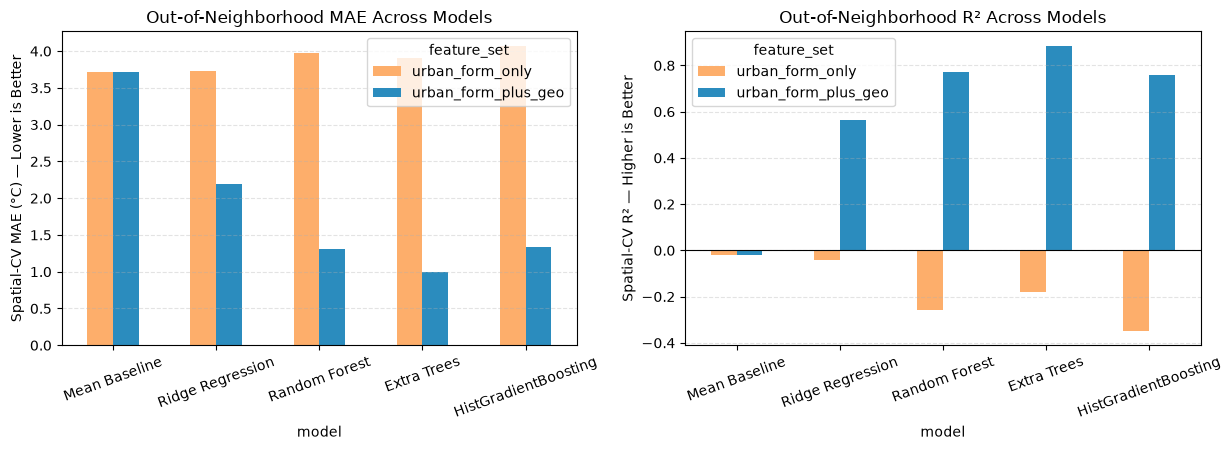

In [6]:
piv_mae = results_df.pivot(index="model", columns="feature_set", values="mae_c").loc[list(build_models().keys())]
piv_r2 = results_df.pivot(index="model", columns="feature_set", values="r2").loc[list(build_models().keys())]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
piv_mae.plot(kind="bar", ax=axes[0], color=["#fdae6b", "#2b8cbe"])
axes[0].set_ylabel("Spatial-CV MAE (°C) — Lower is Better")
axes[0].set_title("Out-of-Neighborhood MAE Across Models")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", linestyle="--", alpha=0.35)

piv_r2.plot(kind="bar", ax=axes[1], color=["#fdae6b", "#2b8cbe"])
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_ylabel("Spatial-CV R² — Higher is Better")
axes[1].set_title("Out-of-Neighborhood R² Across Models")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

## 4. What Did the Models Actually Learn? (Ridge Weights & Permutation Importance)
* **Ridge standardized coefficients** show the linear direction (+ heats up, - cools down) per 1 standard deviation change in each feature.
* **Permutation importance** on `Extra Trees` measures how much the out-of-neighborhood MAE worsens (in °C) when we randomly shuffle one feature at a time on held-out test folds.

Standardized Ridge Coefficients (°C per 1 SD):
 dist_to_coast_km           3.505
osm_green_pct             -0.401
osm_building_count        -0.327
elevation_m                0.283
osm_parking_pct            0.250
dist_to_dtla_km            0.218
osm_industrial_comm_pct   -0.196
osm_major_road_m           0.123
osm_building_pct           0.077
osm_residential_pct        0.055
osm_road_length_m         -0.049
osm_water_pct              0.034
dtype: float64


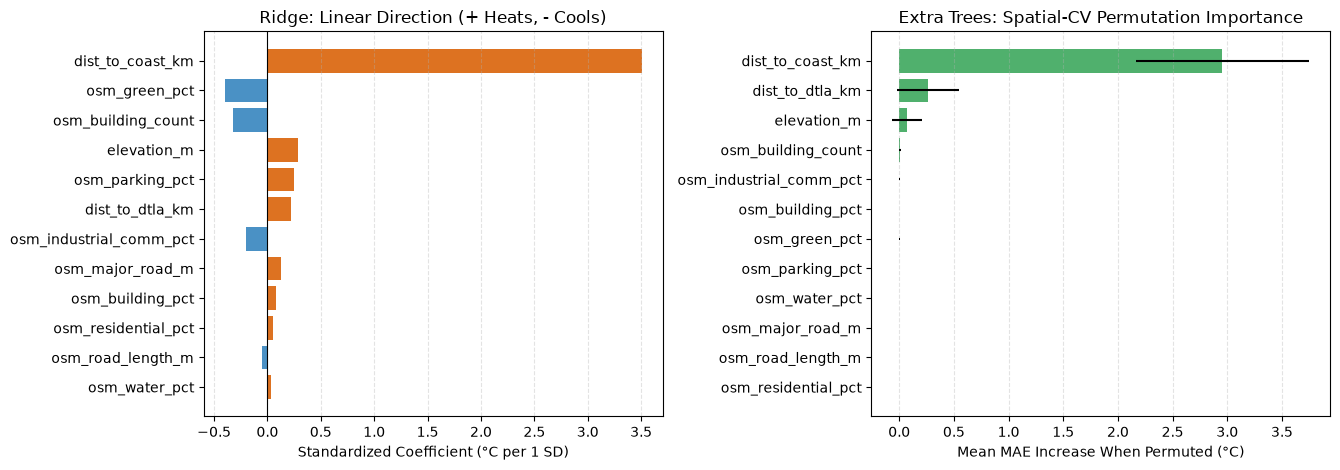

In [7]:
cols_geo = FEATURE_SETS["urban_form_plus_geo"]
ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(df[cols_geo], y)
ridge_coefs = pd.Series(ridge_pipe.named_steps["ridge"].coef_, index=cols_geo).sort_values(key=abs, ascending=False)
print("Standardized Ridge Coefficients (°C per 1 SD):\n", ridge_coefs.round(3))

# 5-fold held-out permutation importance for Extra Trees
fold_imps = []
for tr_idx, te_idx in cv.split(df[cols_geo], y, groups):
    m = build_models()["Extra Trees"]
    m.fit(df[cols_geo].iloc[tr_idx], y[tr_idx])
    perm = permutation_importance(
        m, df[cols_geo].iloc[te_idx], y[te_idx],
        n_repeats=10, random_state=42, scoring="neg_mean_absolute_error"
    )
    fold_imps.append(perm.importances_mean)

imp_df = pd.DataFrame({
    "feature": cols_geo,
    "mae_increase_c": np.mean(fold_imps, axis=0),
    "std_c": np.std(fold_imps, axis=0),
}).sort_values("mae_increase_c", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

rc_sorted = ridge_coefs.iloc[::-1]
rc_colors = ["#d95f02" if v > 0 else "#3182bd" for v in rc_sorted]
axes[0].barh(rc_sorted.index, rc_sorted.to_numpy(), color=rc_colors, alpha=0.88)
axes[0].axvline(0.0, color="black", linewidth=0.8)
axes[0].set_xlabel("Standardized Coefficient (°C per 1 SD)")
axes[0].set_title("Ridge: Linear Direction (+ Heats, - Cools)")
axes[0].grid(axis="x", linestyle="--", alpha=0.35)

top = imp_df.iloc[::-1]
axes[1].barh(top["feature"], top["mae_increase_c"], xerr=top["std_c"], color="#31a354", alpha=0.85)
axes[1].set_xlabel("Mean MAE Increase When Permuted (°C)")
axes[1].set_title("Extra Trees: Spatial-CV Permutation Importance")
axes[1].grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## 5. Error & Residual Analysis: Where Does `Extra Trees` Miss?
Even with `MAE = 0.99 °C`, looking at **which neighborhoods** have the largest prediction errors (`predicted - actual`) tells us what physical signals are still missing (for example, wind corridors, canyon shading, or local industrial/port microclimates).

Top 10 Highest-Error Neighborhoods (Extra Trees Spatial-CV):
                                           actual_mean_c  pred_mean_c  \
neighborhood_name       zone                                            
Long Beach / Wilmington harbor_industrial         29.477       25.717   
Woodland Hills          west_valley               35.050       31.402   
Griffith Park           park_hills                29.701       32.999   
Venice                  coastal                   21.247       24.025   
Northridge              valley                    36.437       33.862   
Hollywood               urban_core                28.939       30.785   
Compton                 south_la                  30.640       28.875   
Watts                   south_la                  30.381       29.022   
Arcadia                 sgv_foothills             35.261       33.978   
Torrance                south_bay                 24.879       26.052   

                                           signed_err_c  mae_c

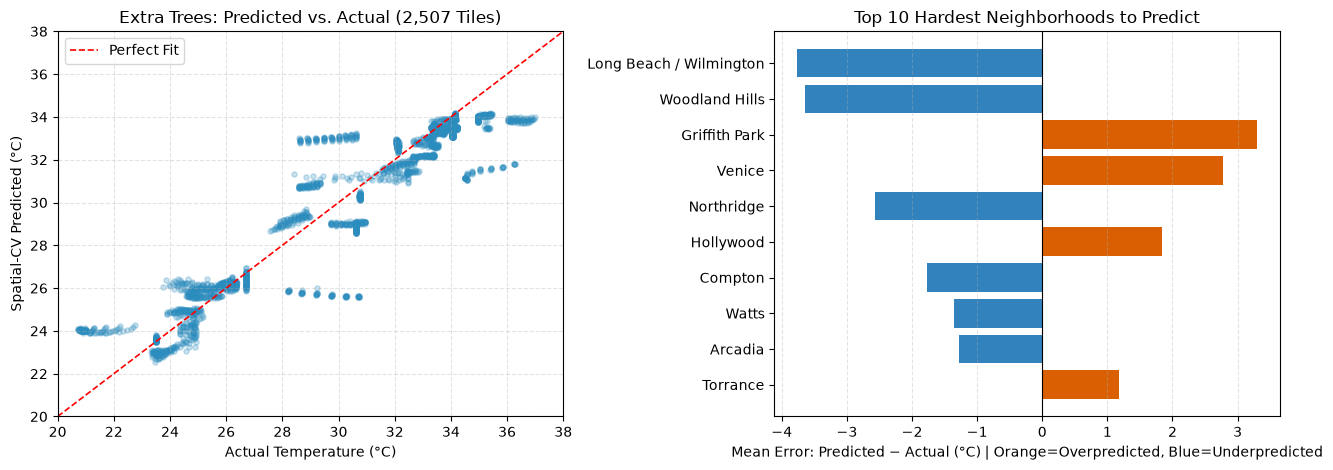

In [8]:
df["pred_et"] = oof_store["urban_form_plus_geo"]["Extra Trees"]
df["error_c"] = df["pred_et"] - df["average_temperature"]
df["abs_error_c"] = df["error_c"].abs()

nb_err = (
    df.groupby(["neighborhood_name", "zone"])
    .agg(
        actual_mean_c=("average_temperature", "mean"),
        pred_mean_c=("pred_et", "mean"),
        signed_err_c=("error_c", "mean"),
        mae_c=("abs_error_c", "mean"),
    )
    .sort_values("mae_c", ascending=False)
)
print("Top 10 Highest-Error Neighborhoods (Extra Trees Spatial-CV):")
display_err = nb_err.head(10).round(3)
print(display_err)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(df["average_temperature"], df["pred_et"], alpha=0.25, s=14, color="#2b8cbe")
lims = [20, 38]
axes[0].plot(lims, lims, "r--", linewidth=1.2, label="Perfect Fit")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual Temperature (°C)")
axes[0].set_ylabel("Spatial-CV Predicted (°C)")
axes[0].set_title("Extra Trees: Predicted vs. Actual (2,507 Tiles)")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend()

worst = nb_err.head(10).iloc[::-1]
bar_colors = ["#d95f02" if v > 0 else "#3182bd" for v in worst["signed_err_c"]]
axes[1].barh(worst.index.get_level_values(0), worst["signed_err_c"], color=bar_colors)
axes[1].axvline(0.0, color="black", linewidth=0.8)
axes[1].set_xlabel("Mean Error: Predicted − Actual (°C) | Orange=Overpredicted, Blue=Underpredicted")
axes[1].set_title("Top 10 Hardest Neighborhoods to Predict")
axes[1].grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## 6. Deep Dive: Within-Neighborhood Micro-Heat (`temp_anomaly_c`)
Finally, what happens if we **remove** the macro-climate entirely by predicting `temp_anomaly_c = tile_temp - neighborhood_mean_temp` using only local OpenStreetMap urban-form features?

This tests whether local buildings, roads, and green space explain **block-to-block** temperature differences inside a single neighborhood, or whether FortyGuard's `100m` `tcm` heatmap is too smooth at that scale.

In [9]:
y_anom = df["average_temperature"] - df.groupby("neighborhood")["average_temperature"].transform("mean")
X_osm = df[URBAN_FORM_FEATURES]

anom_rows = []
for m_name, model in build_models().items():
    preds = cross_val_predict(model, X_osm, y_anom.to_numpy(), groups=groups, cv=cv)
    anom_rows.append({
        "model": m_name,
        "mae_c": round(mean_absolute_error(y_anom, preds), 4),
        "rmse_c": round(root_mean_squared_error(y_anom, preds), 4),
        "r2": round(r2_score(y_anom, preds), 4),
    })

print(f"Within-neighborhood anomaly std = {y_anom.std():.4f} °C")
pd.DataFrame(anom_rows)

Within-neighborhood anomaly std = 0.3544 °C


,model,mae_c,rmse_c,r2
0,Mean Baseline,0.2155,0.3544,0.0000
1,Ridge Regression,0.2299,0.3564,-0.0113
2,Random Forest,0.2435,0.3710,-0.0960
3,Extra Trees,0.2385,0.3650,-0.0609
4,HistGradientBoosting,0.2723,0.3952,-0.2440


## 7. Key Takeaways & Honest Limitations
1. **Spatial validation is essential:** Random KFold dramatically overstates accuracy on 100m gridded data by leaking adjacent tiles; 5-fold `GroupKFold` by neighborhood gives an honest out-of-area benchmark.
2. **Macro-geography drives basin-wide heat:** `dist_to_coast_km` alone accounts for most of the 15.2 °C gradient across LA. With `Urban Form + Macro-Geography`, **`Extra Trees` achieves `MAE = 0.9900 °C` and `R² = 0.8858`** (a ~73% error reduction vs. the `3.72 °C` Mean Baseline).
3. **Within-neighborhood smoothness:** Inside any single 0.8 km² box, `average_temperature` varies by only `std = 0.354 °C`, and OSM land-cover polygons alone barely improve on the zero-anomaly baseline—showing that FortyGuard's 100m `tcm` heatmap primarily captures neighborhood/meso-scale thermal patterns rather than sharp building-by-building microclimates.
4. **Scope caveat:** All 2,507 tiles come from a single summer afternoon snapshot (`2024-07-15 14:00`) in one metro region (Los Angeles), so temporal and cross-city generalization remain **Not tested**.